# Load the Dataset

In [1]:
import pandas as pd

data = pd.read_csv('D:\FYP\Code\Dataset\downsampled_data.csv')

In [36]:
X = data.drop(columns=['activity', 'id', 'time', 'rssi_1', 'rssi_2'])

Y  = data['activity']

In [37]:
Y

0         4
1         4
2         4
3         4
4         4
         ..
116570    0
116571    0
116572    0
116573    0
116574    0
Name: activity, Length: 116575, dtype: int64

# Principle Component Analysis

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=1, svd_solver='full')

pca.fit(X)

PCA(n_components=1, svd_solver='full')

In [27]:
from joblib import dump

dump(pca, 'pca_model_n=1.joblib')

['pca_model_n=1.joblib']

In [28]:
X_pca = pd.DataFrame(pca.transform(X))

In [29]:
X_pca.shape

(116575, 1)

Explained variance ratio of the principal component(s)

In [30]:
explained_variance_ratio = pca.explained_variance_ratio_
print(explained_variance_ratio)

[0.43722543]


In [34]:
X_pca

,0
0,-33.968479
1,-34.854806
2,-35.048804
3,-33.586920
4,-34.826279
...,...
116570,-43.286276
116571,-43.412489
116572,-44.532264
116573,-47.292591


<Axes: >

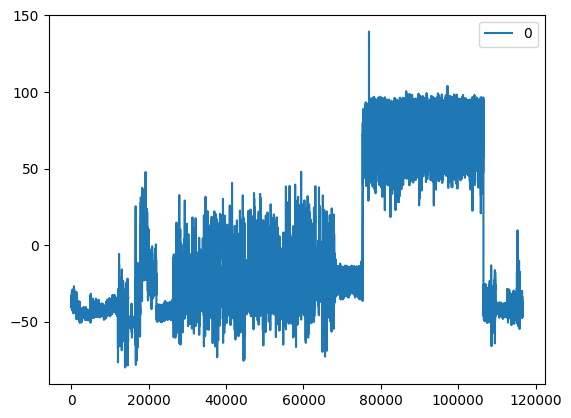

In [35]:
X_pca.plot()


Save PCA data to csv

In [38]:
X_pca.to_csv('pca_n=1.csv', index=False)

# Apply low pass filter

In [39]:
from scipy.signal import butter, filtfilt

# Filter parameters
cutoff_frequency = 10  # Cutoff frequency in Hz
sampling_frequency = 25  # Sampling frequency in Hz, adjust according to your data
filter_order = 5

def butter_lowpass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

Apply the low pass filter to the principal component

In [41]:
X_pca_filtered = butter_lowpass_filter(X_pca[0], cutoff_frequency, sampling_frequency, filter_order)

Save the PCA model

In [42]:
dump(pca, 'pca_model_n=1_filtered.joblib')

['pca_model_n=1_filtered.joblib']

Convert filtered principal component to DataFrame

<Axes: >

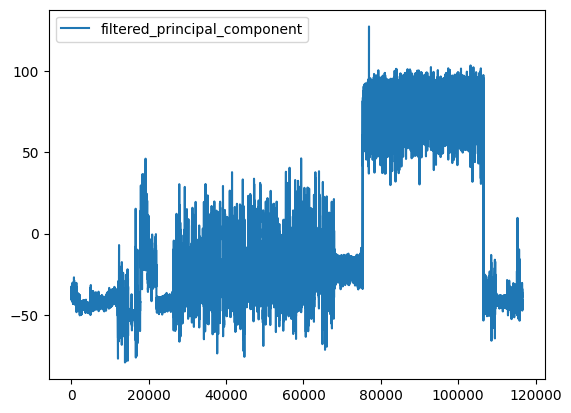

In [47]:
X_pca_filtered_df = pd.DataFrame(X_pca_filtered, columns=['filtered_principal_component'])

X_pca_filtered_df.plot()

### Filter with different parameters

(Parameters we used)

In [48]:
# Define the filter parameters
order = 4
cutoff_freq = 0.005

# Create the filter coefficients
b, a = butter(order, cutoff_freq, btype='low', analog=False, output='ba')

filtered_data = X_pca.apply(lambda x: filtfilt(b, a, x))

<Axes: >

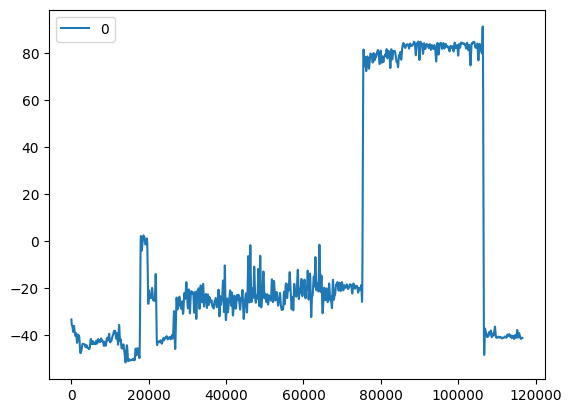

In [51]:
X_pca_filtered_df_new = pd.DataFrame(filtered_data, columns=[0])

X_pca_filtered_df_new.plot()

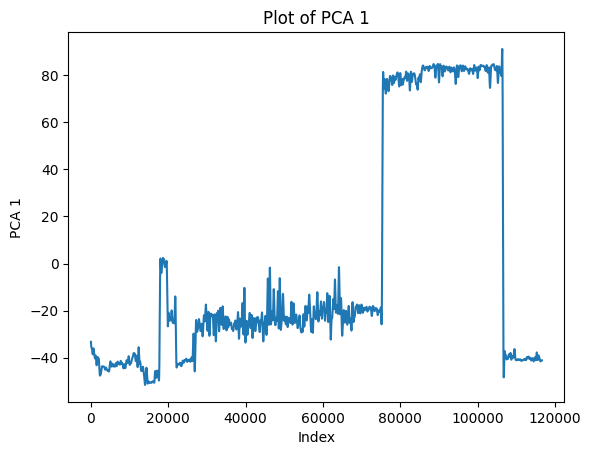

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.lineplot(data=filtered_data[0])
plt.xlabel('Index')
plt.ylabel(f'PCA {1}')
plt.title(f'Plot of PCA {1}')
plt.show()


# Feature Extraction

## Get wavelet variances

In [21]:
activity_zero_rows = X_pca[Y == 0]

activity_zero_rows_count = len(activity_zero_rows)
print(activity_zero_rows_count)

45750


In [22]:
activity_one_rows = X_pca[Y == 1]

activity_one_rows_count = len(activity_one_rows)
print(activity_one_rows_count)

16850


In [23]:
activity_two_rows = X_pca[Y == 2]

activity_two_rows_count = len(activity_two_rows)
print(activity_two_rows_count)

14275


In [24]:
activity_three_rows = X_pca[Y == 3]

activity_three_rows_count = len(activity_three_rows)
print(activity_three_rows_count)

10950


In [25]:
activity_four_rows = X_pca[Y == 4]

activity_four_rows_count = len(activity_four_rows)
print(activity_four_rows_count)

15923


In [26]:
activity_five_rows = X_pca[Y == 5]

activity_five_rows_count = len(activity_five_rows)
print(activity_five_rows_count)

12827


In [27]:
import pywt
import numpy as np

In [28]:
wavelet_name = 'gaus1'

scales = np.arange(1, 128)


In [35]:
wavelet_variances = np.empty((0, 26))

for i in range(activity_zero_rows_count // 25):
    csi = activity_zero_rows.iloc[i*25:i*25+25, 0]
    coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
    wavelet_variance = np.sum(coefficients**2, axis=0)
    wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 0)))

In [36]:
for i in range(activity_one_rows_count // 25):
	csi = activity_one_rows.iloc[i*25:i*25+25, 0]
	coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
	wavelet_variance = np.sum(coefficients**2, axis=0)
	wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 1)))

In [37]:
for i in range(activity_two_rows_count // 25):
	csi = activity_two_rows.iloc[i*25:i*25+25, 0]
	coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
	wavelet_variance = np.sum(coefficients**2, axis=0)
	wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 2)))

In [38]:
for i in range(activity_three_rows_count // 25):
	csi = activity_three_rows.iloc[i*25:i*25+25, 0]
	coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
	wavelet_variance = np.sum(coefficients**2, axis=0)
	wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 3)))

In [39]:
for i in range(activity_four_rows_count // 25):
	csi = activity_four_rows.iloc[i*25:i*25+25, 0]
	coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
	wavelet_variance = np.sum(coefficients**2, axis=0)
	wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 4)))

In [41]:
for i in range(activity_five_rows_count // 25):
	csi = activity_five_rows.iloc[i*25:i*25+25, 0]
	coefficients, frequencies = pywt.cwt(csi, scales, wavelet_name)
	wavelet_variance = np.sum(coefficients**2, axis=0)
	wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, 5)))

In [42]:
wavelet_variances.shape

(4662, 26)

In [43]:
wav = pd.DataFrame(wavelet_variances)

wav.to_csv('wavelet.csv', index=False)

In [6]:
#optional
import pandas as pd

wav = pd.read_csv('wavelet.csv')

In [10]:
wav.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,844246.771846,766322.702933,676362.874956,582653.055304,487632.724253,393843.605076,305121.373537,223931.271079,154857.408559,94572.790876,...,93226.921534,153166.942791,222545.054532,303888.999399,391866.465254,486724.818599,582024.721112,676678.812110,766812.986354,0.0
1,851375.348222,774111.417021,683931.984637,589071.573066,493228.136977,398480.843524,308753.153052,226674.010000,156393.591442,95865.394673,...,93312.556147,153424.613589,223178.694361,305063.310803,394014.921374,489715.817570,586245.862100,681382.519576,772321.154907,0.0
2,884561.046834,805462.679879,712995.277572,616338.739829,518113.814785,420973.478929,328356.639683,243127.911778,169764.937039,105944.804686,...,90432.600876,151332.371735,222692.063303,307100.479375,399330.775529,498983.142903,599785.024406,699926.556974,796329.385742,0.0
3,875623.235671,791263.938793,693748.534380,592467.523342,491291.727575,392664.217563,300174.393228,216875.012549,146730.350371,86788.007042,...,108194.982183,172722.918894,246321.839503,331850.274237,423853.145715,521895.203145,620060.792082,716353.006580,807798.021463,0.0
4,862933.383222,782687.639338,689386.984217,592237.854560,493949.114379,397407.064741,306431.404397,223540.773615,153226.074482,92582.391814,...,98969.366795,160784.411899,231720.006889,314865.545939,404502.003237,500760.392064,597458.846946,693382.098300,785308.674817,0.0


In [13]:
X = wav.drop(columns=['25'])

Y = wav['25']

In [14]:
X.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,844246.771846,766322.702933,676362.874956,582653.055304,487632.724253,393843.605076,305121.373537,223931.271079,154857.408559,94572.790876,...,48111.797898,93226.921534,153166.942791,222545.054532,303888.999399,391866.465254,486724.818599,582024.721112,676678.812110,766812.986354
1,851375.348222,774111.417021,683931.984637,589071.573066,493228.136977,398480.843524,308753.153052,226674.010000,156393.591442,95865.394673,...,47995.749940,93312.556147,153424.613589,223178.694361,305063.310803,394014.921374,489715.817570,586245.862100,681382.519576,772321.154907
2,884561.046834,805462.679879,712995.277572,616338.739829,518113.814785,420973.478929,328356.639683,243127.911778,169764.937039,105944.804686,...,45050.099684,90432.600876,151332.371735,222692.063303,307100.479375,399330.775529,498983.142903,599785.024406,699926.556974,796329.385742
3,875623.235671,791263.938793,693748.534380,592467.523342,491291.727575,392664.217563,300174.393228,216875.012549,146730.350371,86788.007042,...,58605.868118,108194.982183,172722.918894,246321.839503,331850.274237,423853.145715,521895.203145,620060.792082,716353.006580,807798.021463
4,862933.383222,782687.639338,689386.984217,592237.854560,493949.114379,397407.064741,306431.404397,223540.773615,153226.074482,92582.391814,...,52075.319477,98969.366795,160784.411899,231720.006889,314865.545939,404502.003237,500760.392064,597458.846946,693382.098300,785308.674817


In [15]:
Y.head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: 25, dtype: float64

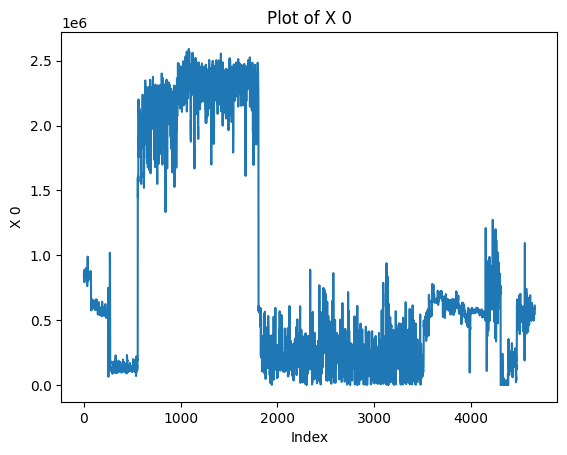

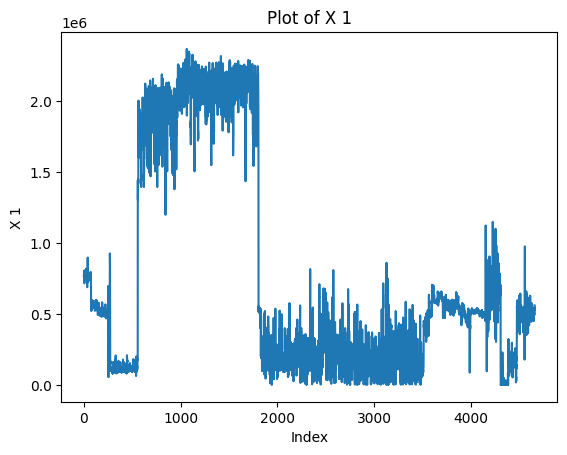

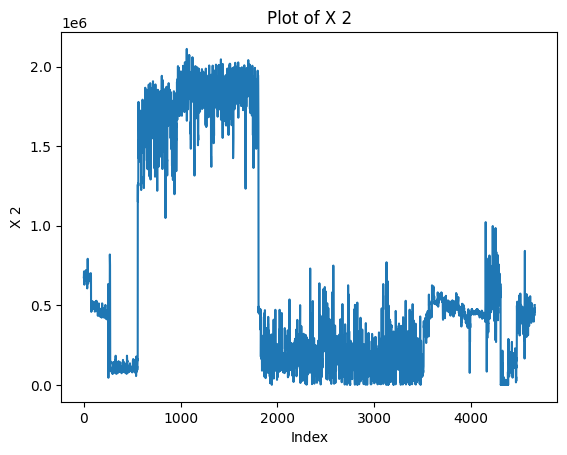

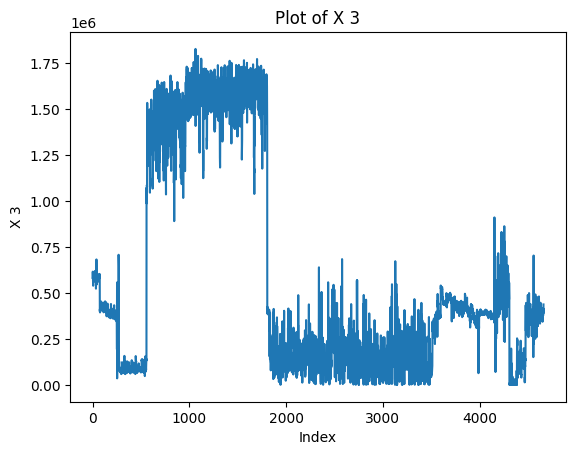

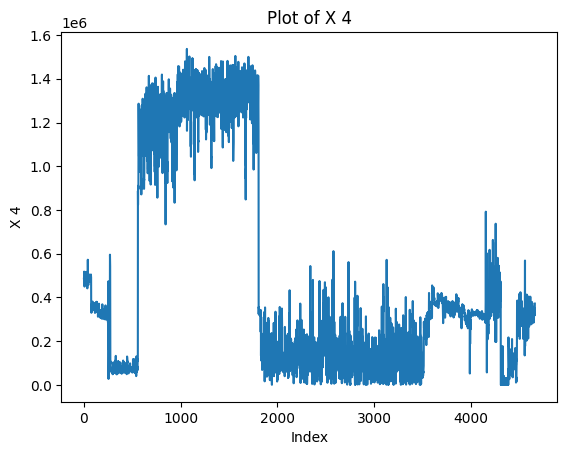

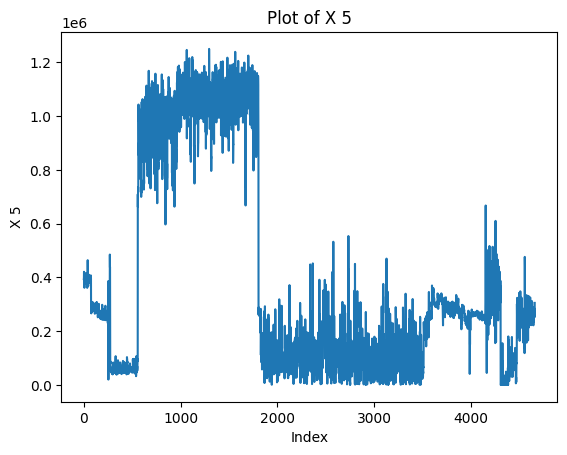

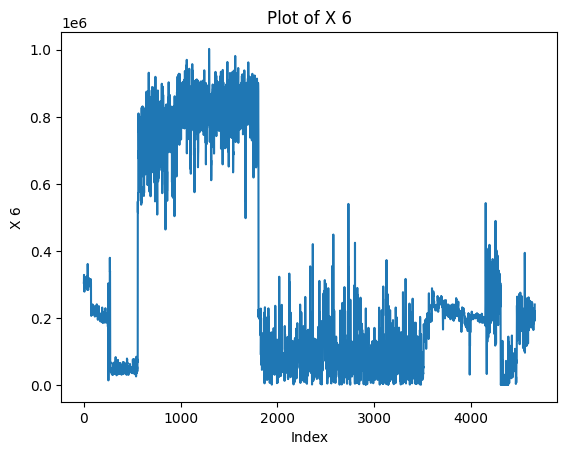

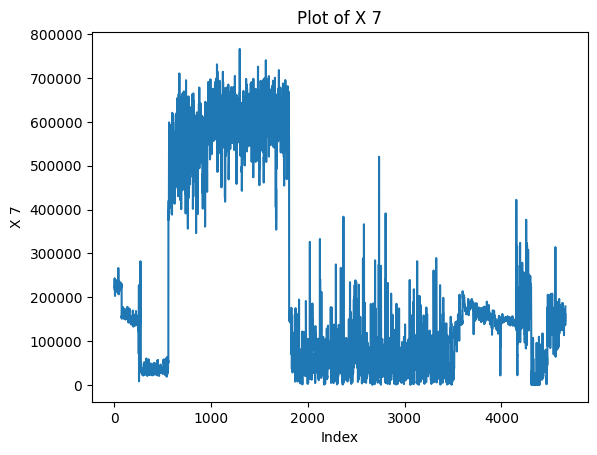

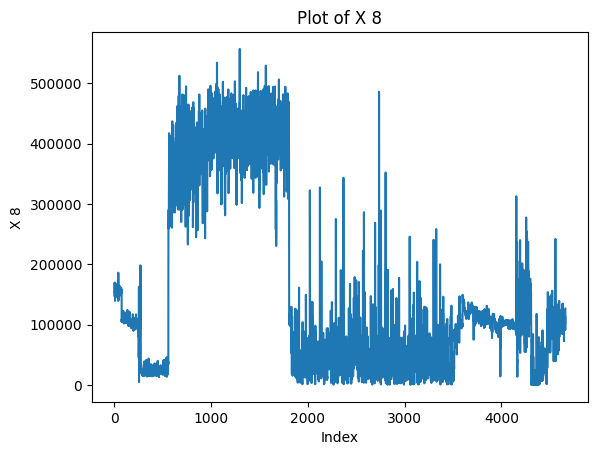

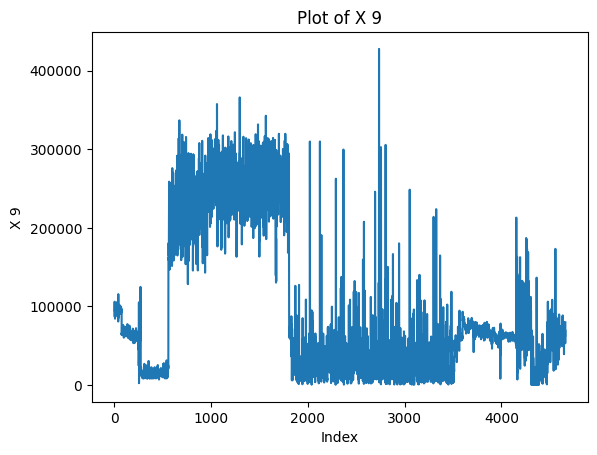

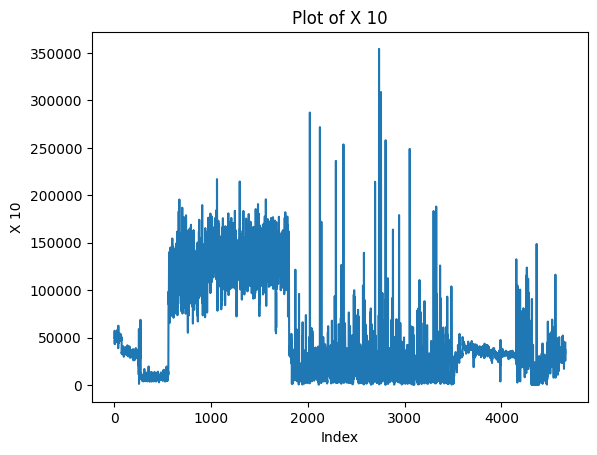

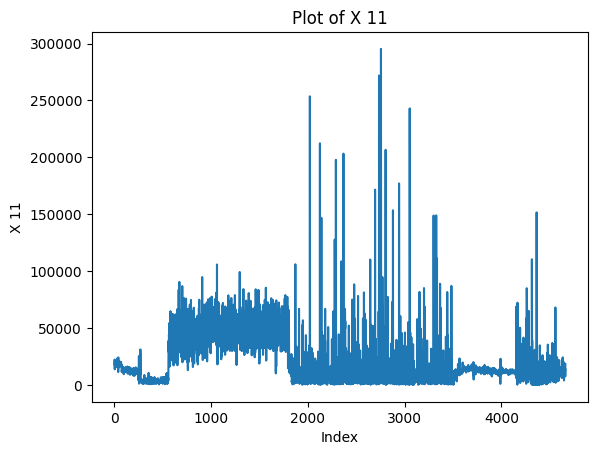

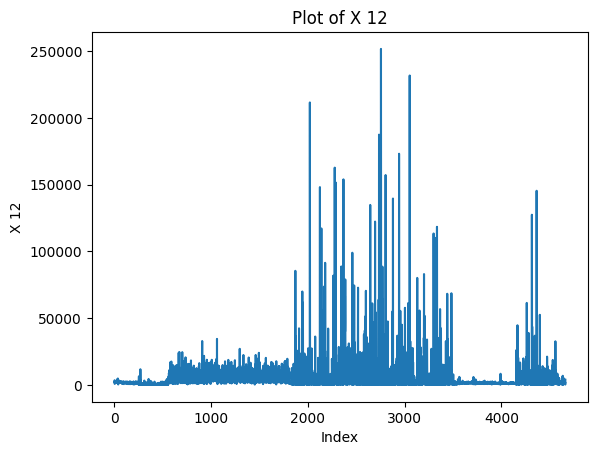

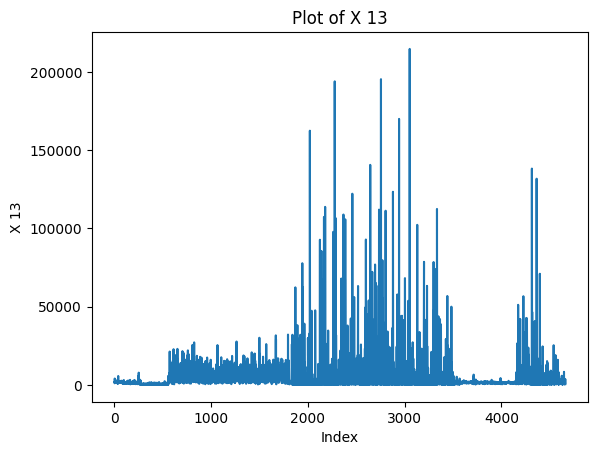

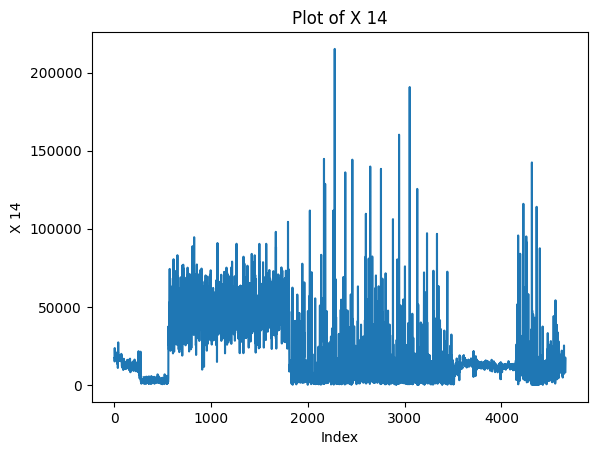

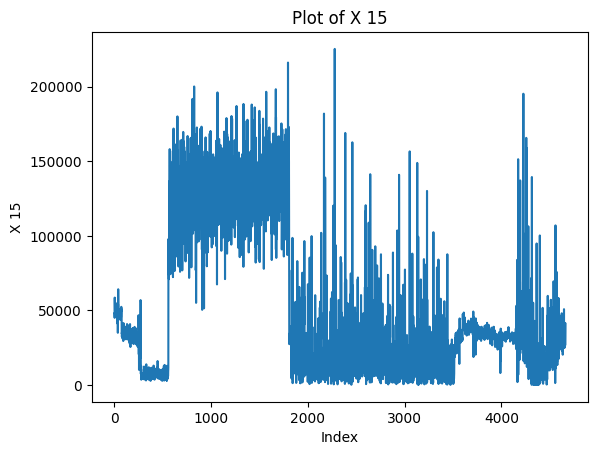

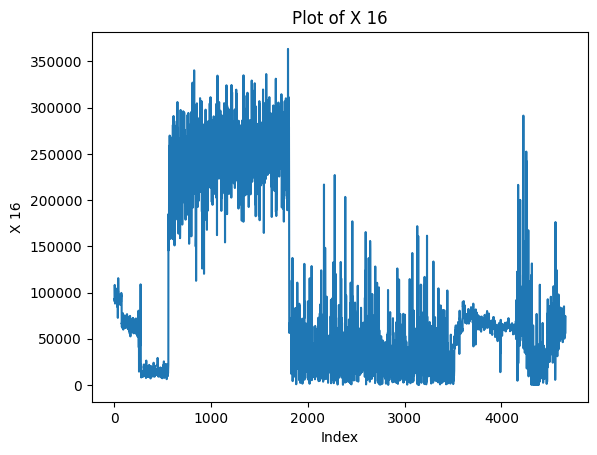

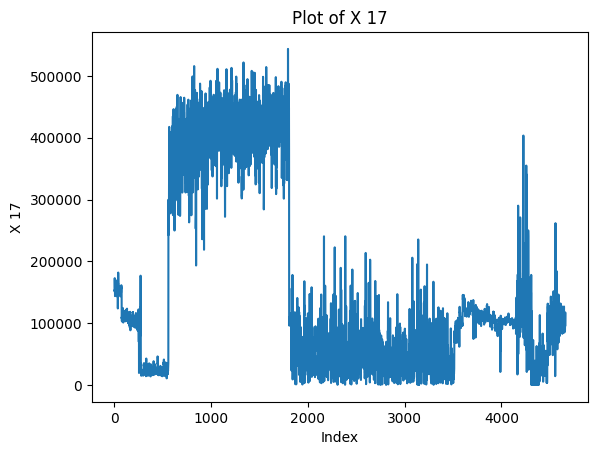

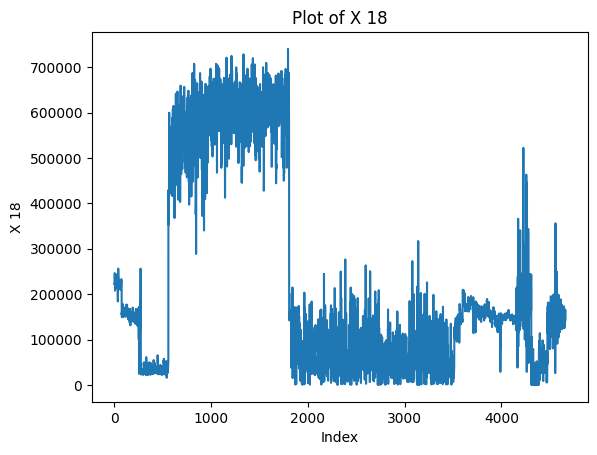

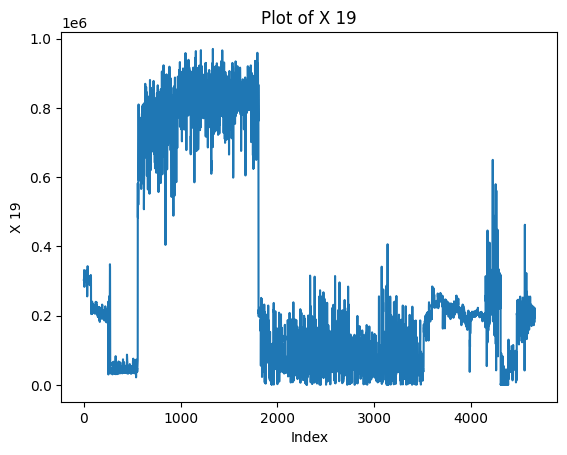

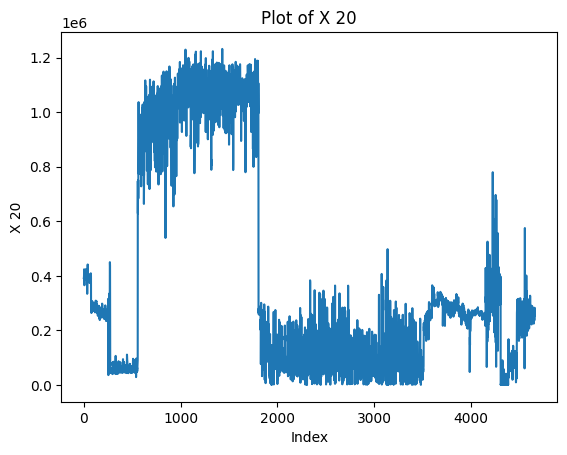

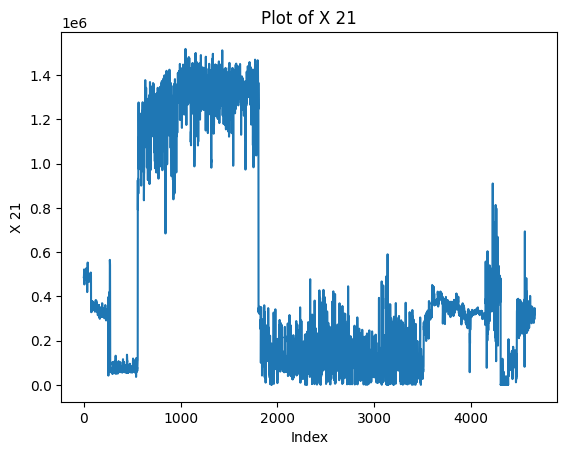

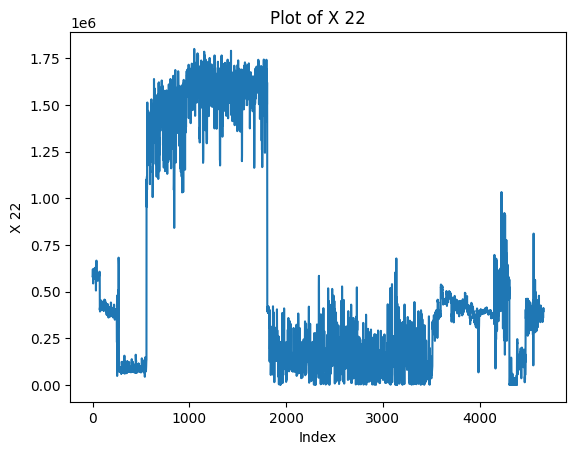

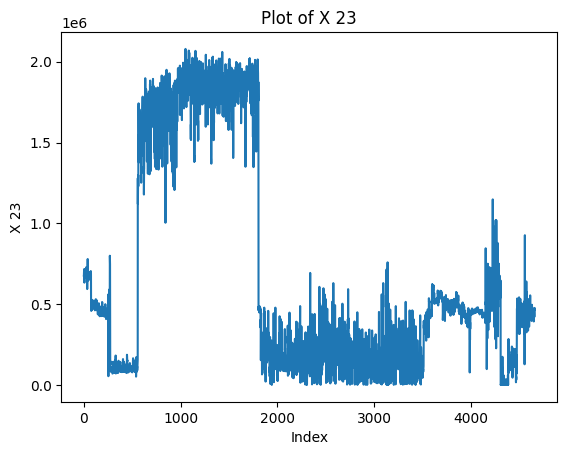

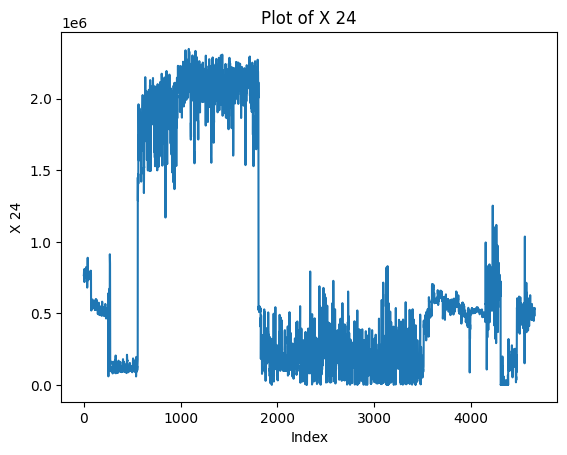

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

for column in X.columns:
    sns.lineplot(data=X[column])
    plt.xlabel('Index')
    plt.ylabel(f'X {column}')
    plt.title(f'Plot of X {column}')
    plt.show()
